In [1]:
import random
import numpy as np

In [2]:
%timeit [random.random() for _ in range(100_000)]

2.1 ms ± 36.4 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [3]:
%timeit np.random.rand(100_000)

176 μs ± 219 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


# Lesson 3 GPU benchmark
Time to multiply two 4000x4000 matrices on each device.

In [4]:
%%writefile benchmark.csv
device,time_ms
Windows laptop CPU,808
MacBook Air M4 CPU,66.6
MacBook Air M4 GPU (MPS),43.7
Colab T4 GPU fp32,28.3
Colab T4 GPU fp16,2.8

Overwriting benchmark.csv


In [5]:
import pandas as pd
df = pd.read_csv("benchmark.csv")
df["speedup"] = df["time_ms"].iloc[0] / df["time_ms"]
df

,device,time_ms,speedup
0,Windows laptop CPU,808.0,1.000000
1,MacBook Air M4 CPU,66.6,12.132132
2,MacBook Air M4 GPU (MPS),43.7,18.489703
3,Colab T4 GPU fp32,28.3,28.551237
4,Colab T4 GPU fp16,2.8,288.571429


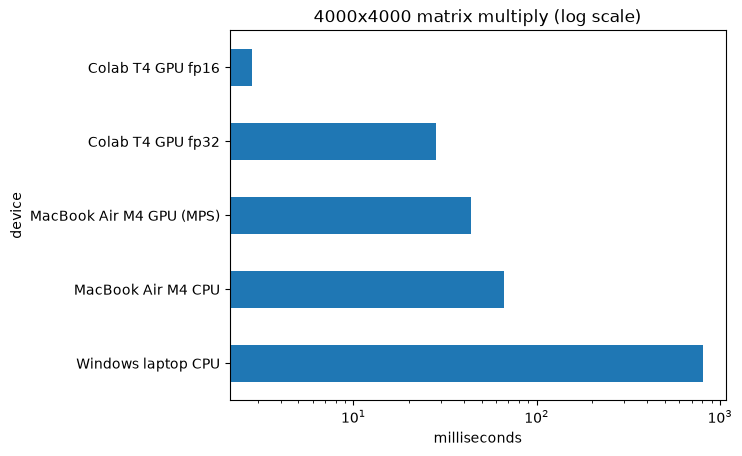

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
df.plot.barh(x="device", y="time_ms", logx=True, legend=False,
             title="4000x4000 matrix multiply (log scale)")
plt.xlabel("milliseconds")
plt.show()